# Practical No. 03: Autoencoder and Variational Autoencoder for Image Reconstruction

## Objective
Implement an Autoencoder (AE) and a Variational Autoencoder (VAE) for image reconstruction and generation, then compare their reconstruction performance and latent-space behavior.

## Dataset
This notebook uses the MNIST handwritten digit dataset through TensorFlow/Keras. It contains 60,000 training images and 10,000 test images of grayscale handwritten digits, each sized 28 × 28 pixels. The dataset is downloaded automatically on first use.

## Learning outcomes
- Prepare and normalize image data.
- Build an Autoencoder and understand its encoder, decoder, and latent representation.
- Build a VAE using mean, log-variance, reparameterization, reconstruction loss, and KL divergence.
- Compare reconstructions with mean squared error (MSE).
- Generate new digit-like images from the VAE latent space.
- Visualize the learned latent representation and interpret the results.

## Requirements
Python 3.9+, TensorFlow, NumPy, Matplotlib, and scikit-learn.

Install with `pip install tensorflow numpy matplotlib scikit-learn`.


## 1. Reproducibility and imports

Random seeds help make runs more repeatable. Exact reproducibility can still vary by hardware and certain TensorFlow operations.

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, Model
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.21.0
NumPy version: 2.1.3


## 2. Load and prepare MNIST

Pixel values are scaled to [0, 1]. Each 28 × 28 image is flattened to 784 values because the models below use fully connected layers. The labels are retained for coloring the latent-space plot.

In [2]:
(x_train_raw, y_train), (x_test_raw, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train_raw.astype("float32") / 255.0
x_test = x_test_raw.astype("float32") / 255.0

x_train = x_train.reshape((-1, 784))
x_test = x_test.reshape((-1, 784))

print("Training images:", x_train.shape)
print("Test images:", x_test.shape)
print("Pixel range:", float(x_train.min()), "to", float(x_train.max()))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 784)
Test images: (10000, 784)
Pixel range: 0.0 to 1.0


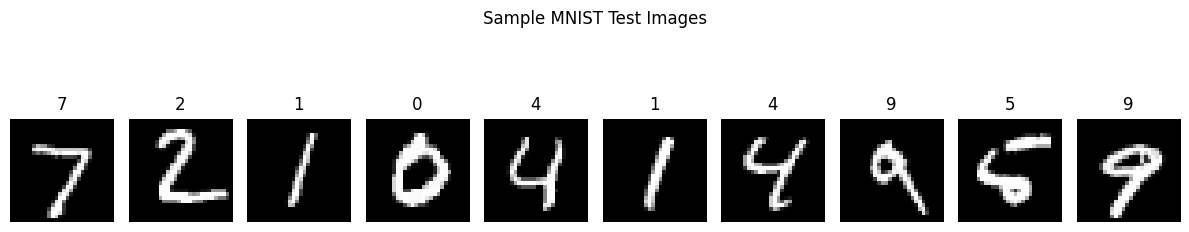

In [3]:
# Preview original test images
plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_test_raw[i], cmap="gray")
    plt.title(str(y_test[i]))
    plt.axis("off")
plt.suptitle("Sample MNIST Test Images")
plt.tight_layout()
plt.show()

## 3. Build and train the Autoencoder

The encoder maps a 784-value image to a 32-dimensional latent vector. The decoder maps that vector back to 784 pixel values. Binary cross-entropy is used as the reconstruction loss.

In [4]:
# Clear previous Keras models while keeping the selected random seed
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

input_img = layers.Input(shape=(784,), name="image_input")
h = layers.Dense(256, activation="relu", name="ae_encoder_256")(input_img)
h = layers.Dense(128, activation="relu", name="ae_encoder_128")(h)
latent = layers.Dense(32, activation="relu", name="ae_latent")(h)

h = layers.Dense(128, activation="relu", name="ae_decoder_128")(latent)
h = layers.Dense(256, activation="relu", name="ae_decoder_256")(h)
output_img = layers.Dense(784, activation="sigmoid", name="ae_reconstruction")(h)

autoencoder = Model(input_img, output_img, name="autoencoder")
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_encoder_256 (Dense)          │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_encoder_128 (Dense)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_latent (Dense)               │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_decoder_128 (Dense)          │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_decoder_256 (Dense)          │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_reconstruction (Dense)       │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 476,720 (1.82 MB)

 Trainable params: 476,720 (1.82 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
AE_EPOCHS = 10
BATCH_SIZE = 256

history_ae = autoencoder.fit(
    x_train, x_train,
    epochs=AE_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(x_test, x_test),
    verbose=1
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - loss: 0.2186 - val_loss: 0.1445
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1301 - val_loss: 0.1180
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1145 - val_loss: 0.1088
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1072 - val_loss: 0.1031
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1015 - val_loss: 0.0983
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0975 - val_loss: 0.0953
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0949 - val_loss: 0.0931
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0929 - val_loss: 0.0916
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0912 - val_loss: 0.0900
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0898 - val_loss: 0.0889


## 4. Autoencoder reconstruction results

The first row shows original images and the second row shows the Autoencoder reconstructions.

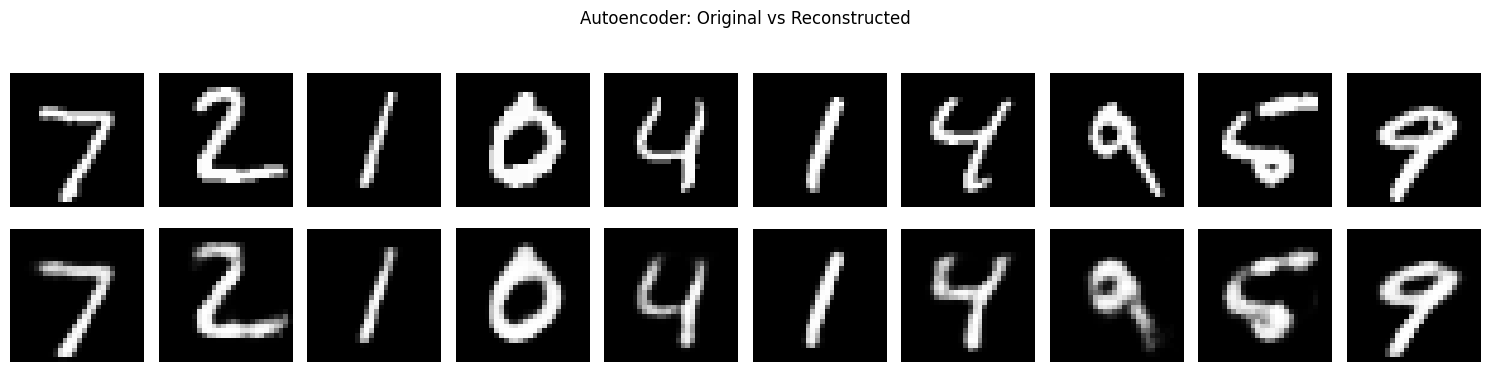

In [6]:
ae_reconstructed = autoencoder.predict(x_test[:10], verbose=0)

plt.figure(figsize=(15, 4))
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

    plt.subplot(2, 10, i + 11)
    plt.imshow(ae_reconstructed[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("AE output")

plt.suptitle("Autoencoder: Original vs Reconstructed")
plt.tight_layout()
plt.show()

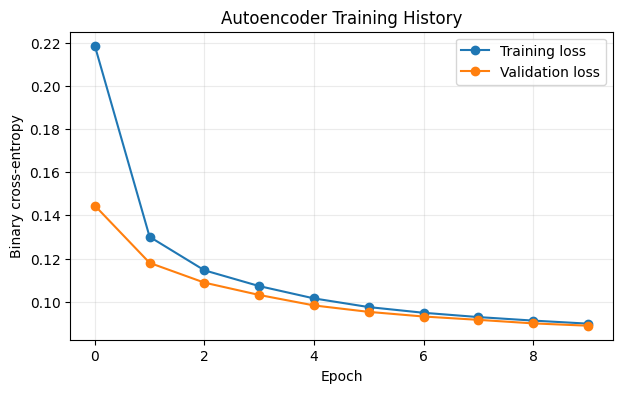

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(history_ae.history["loss"], marker="o", label="Training loss")
plt.plot(history_ae.history["val_loss"], marker="o", label="Validation loss")
plt.title("Autoencoder Training History")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 5. Build and train the Variational Autoencoder (VAE)

The VAE encoder predicts a mean and log-variance for each input. The sampling layer uses the reparameterization trick:

`z = mean + exp(0.5 * log_variance) * epsilon`, where `epsilon` is sampled from a standard normal distribution.

The training objective is reconstruction loss plus KL divergence. The reconstruction loss below is summed across pixels for each image and averaged across the batch; KL divergence is computed per image and averaged across the batch.

In [8]:
LATENT_DIM = 32

class Sampling(layers.Layer):
    def call(self, inputs):
        mean, log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(mean))
        return mean + tf.exp(0.5 * log_var) * epsilon

# VAE encoder
vae_input = layers.Input(shape=(784,), name="vae_input")
h = layers.Dense(256, activation="relu")(vae_input)
h = layers.Dense(128, activation="relu")(h)
z_mean = layers.Dense(LATENT_DIM, name="z_mean")(h)
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(h)
z = Sampling(name="sampling")([z_mean, z_log_var])

encoder = Model(vae_input, [z_mean, z_log_var, z], name="vae_encoder")

# VAE decoder
latent_input = layers.Input(shape=(LATENT_DIM,), name="latent_input")
h = layers.Dense(128, activation="relu")(latent_input)
h = layers.Dense(256, activation="relu")(h)
vae_output = layers.Dense(784, activation="sigmoid", name="vae_output")(h)
decoder = Model(latent_input, vae_output, name="vae_decoder")

encoder.summary()
decoder.summary()

Model: "vae_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ vae_input           │ (None, 784)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    200,960 │ vae_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 32)        │      4,128 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 32)        │      4,128 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 32)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 242,112 (945.75 KB)

 Trainable params: 242,112 (945.75 KB)

 Non-trainable params: 0 (0.00 B)

Model: "vae_decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ latent_input (InputLayer)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vae_output (Dense)              │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 238,736 (932.56 KB)

 Trainable params: 238,736 (932.56 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
class VAE(Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.reconstruction_loss_tracker = tf.keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            mean, log_var, sampled_z = self.encoder(data, training=True)
            reconstruction = self.decoder(sampled_z, training=True)

            # Sum pixel losses per image, then average across the batch
            per_pixel_loss = tf.keras.backend.binary_crossentropy(
                data, reconstruction
            )
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(per_pixel_loss, axis=1)
            )

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + log_var - tf.square(mean) - tf.exp(log_var),
                    axis=1
                )
            )

            total_loss = reconstruction_loss + kl_loss

        gradients = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {metric.name: metric.result() for metric in self.metrics}

    def call(self, inputs, training=False):
        mean, log_var, sampled_z = self.encoder(inputs, training=training)
        return self.decoder(sampled_z, training=training)

vae = VAE(encoder, decoder, name="vae")
vae.compile(optimizer=tf.keras.optimizers.Adam())
vae.summary()

Model: "vae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vae_encoder (Functional)        │ ((None, 32), (None,    │       242,112 │
│                                 │ 32), (None, 32))       │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vae_decoder (Functional)        │ (None, 784)            │       238,736 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 480,848 (1.83 MB)

 Trainable params: 480,848 (1.83 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
VAE_EPOCHS = 10

history_vae = vae.fit(
    x_train,
    epochs=VAE_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=1
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - kl_loss: 7.4454 - loss: 201.1538 - reconstruction_loss: 193.7085
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - kl_loss: 15.9141 - loss: 145.9868 - reconstruction_loss: 130.0727
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - kl_loss: 18.4200 - loss: 130.8745 - reconstruction_loss: 112.4546
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - kl_loss: 19.3987 - loss: 123.4022 - reconstruction_loss: 104.0034
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - kl_loss: 20.1123 - loss: 118.8387 - reconstruction_loss: 98.7264
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - kl_loss: 20.6550 - loss: 115.6987 - reconstruction_loss: 95.0438
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - kl_loss: 21.1169 - loss: 113.6147 - reconstruction_loss: 92.4978
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - kl_loss: 21.4168 - loss: 112.0274 - reconstruction_loss: 90.6106
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 

## 6. VAE reconstruction results

The VAE uses a sampled latent vector for reconstruction. Because the representation is probabilistic, reconstructions can vary slightly between runs or calls.

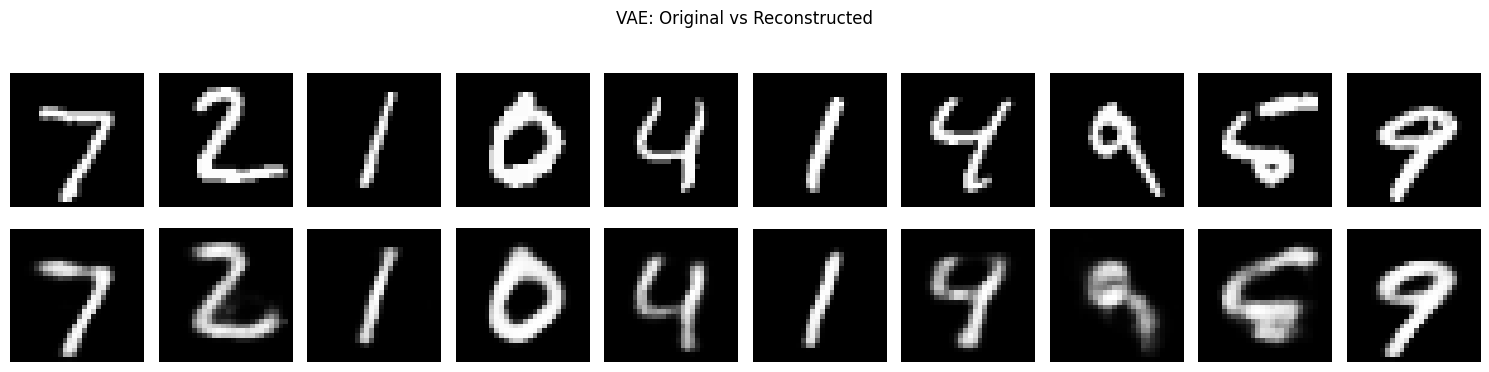

In [11]:
vae_reconstructed = vae.predict(x_test[:10], verbose=0)

plt.figure(figsize=(15, 4))
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

    plt.subplot(2, 10, i + 11)
    plt.imshow(vae_reconstructed[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("VAE output")

plt.suptitle("VAE: Original vs Reconstructed")
plt.tight_layout()
plt.show()

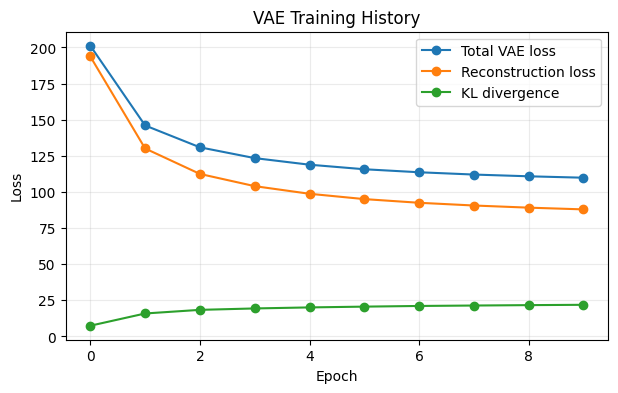

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(history_vae.history["loss"], marker="o", label="Total VAE loss")
plt.plot(
    history_vae.history["reconstruction_loss"],
    marker="o",
    label="Reconstruction loss"
)
plt.plot(history_vae.history["kl_loss"], marker="o", label="KL divergence")
plt.title("VAE Training History")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 7. Generate new images with the VAE

Sample latent vectors from a standard normal distribution and pass them through the trained decoder. These are newly generated images, not reconstructions of test images.

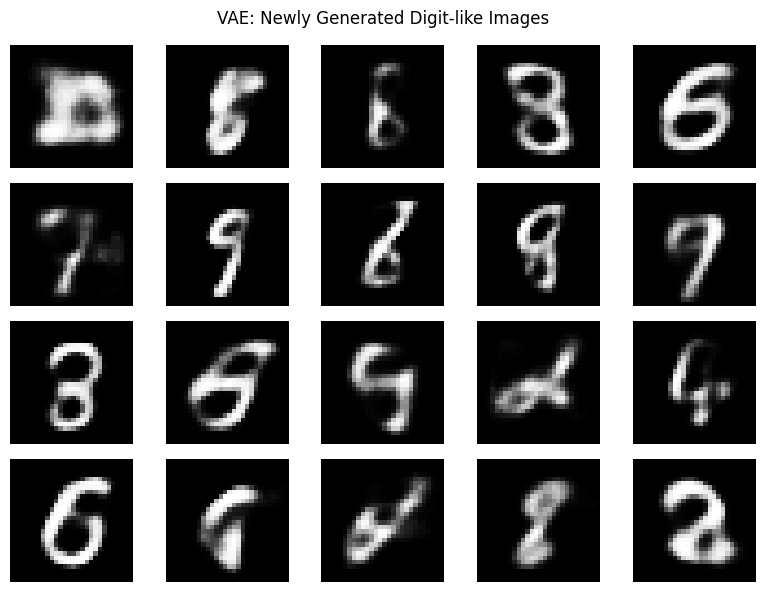

In [13]:
NUM_GENERATED = 20
random_latent_vectors = tf.random.normal((NUM_GENERATED, LATENT_DIM), seed=SEED)
generated_images = decoder.predict(random_latent_vectors, verbose=0)

plt.figure(figsize=(8, 6))
for i in range(NUM_GENERATED):
    plt.subplot(4, 5, i + 1)
    plt.imshow(generated_images[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.suptitle("VAE: Newly Generated Digit-like Images")
plt.tight_layout()
plt.show()

## 8. Quantitative comparison using test-set MSE

MSE measures average squared pixel differences between originals and reconstructions. It is useful for comparing reconstruction fidelity, but it does not measure whether randomly generated images are realistic or diverse.

For a fair comparison, use the encoder's mean for deterministic VAE reconstructions rather than a random sample. This reduces randomness in the evaluation.

In [14]:
# AE reconstruction on the full test set
ae_test_predictions = autoencoder.predict(x_test, batch_size=BATCH_SIZE, verbose=0)

# Deterministic VAE reconstruction using the latent mean
vae_mean_test, _, _ = encoder.predict(x_test, batch_size=BATCH_SIZE, verbose=0)
vae_test_predictions = decoder.predict(vae_mean_test, batch_size=BATCH_SIZE, verbose=0)

ae_mse = float(np.mean(np.square(x_test - ae_test_predictions)))
vae_mse = float(np.mean(np.square(x_test - vae_test_predictions)))

print(f"Autoencoder test MSE: {ae_mse:.6f}")
print(f"VAE test MSE (using latent mean): {vae_mse:.6f}")

if ae_mse < vae_mse:
    print("The Autoencoder has lower pixel-wise reconstruction error in this run.")
elif vae_mse < ae_mse:
    print("The VAE has lower pixel-wise reconstruction error in this run.")
else:
    print("Both models have the same MSE to the displayed precision.")

Autoencoder test MSE: 0.008985
VAE test MSE (using latent mean): 0.012744
The Autoencoder has lower pixel-wise reconstruction error in this run.


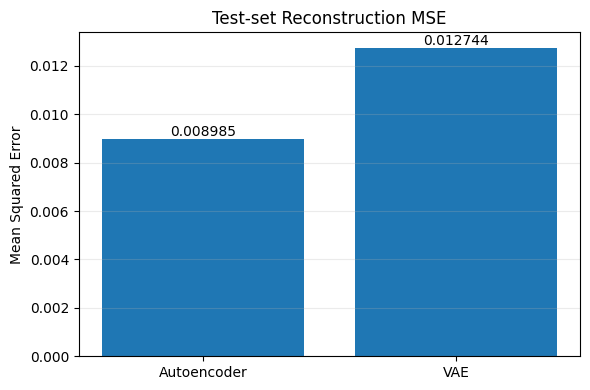

In [15]:
# Side-by-side metric visualization
model_names = ["Autoencoder", "VAE"]
mse_values = [ae_mse, vae_mse]

plt.figure(figsize=(6, 4))
bars = plt.bar(model_names, mse_values)
plt.title("Test-set Reconstruction MSE")
plt.ylabel("Mean Squared Error")
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, mse_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.6f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## 9. Visualize the VAE latent space using PCA

The plot projects the 32-dimensional latent means to two dimensions for visualization. Each point represents a test image and its color is the true digit label. PCA preserves directions of high variance, not necessarily class boundaries; overlapping colors are therefore possible.

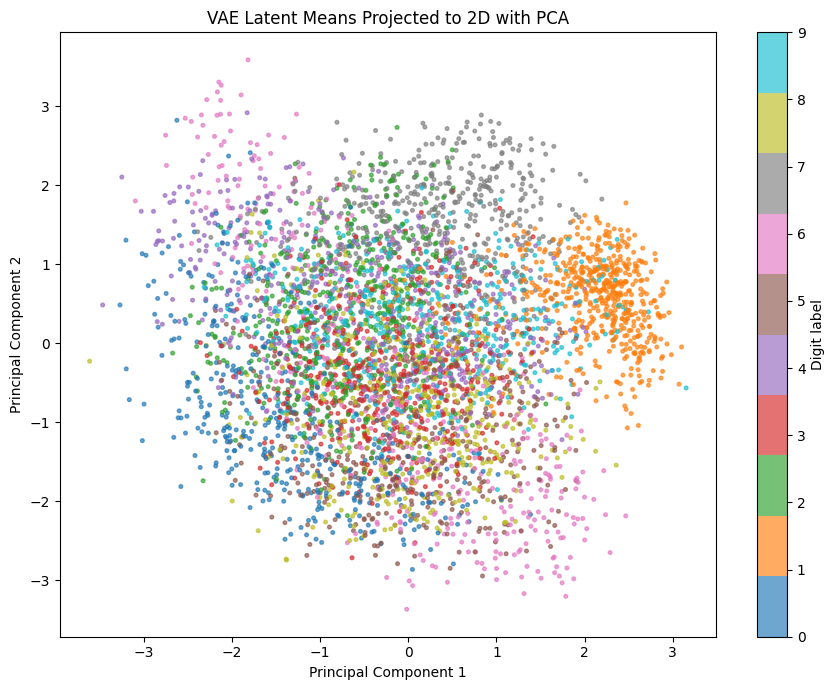

Variance explained by first two components: 18.74%


In [16]:
# Use a subset for a readable plot and quicker PCA visualization
N_PCA = min(5000, len(x_test))
mean_subset = vae_mean_test[:N_PCA]
labels_subset = y_test[:N_PCA]

pca = PCA(n_components=2, random_state=SEED)
z_2d = pca.fit_transform(mean_subset)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(
    z_2d[:, 0],
    z_2d[:, 1],
    c=labels_subset,
    cmap="tab10",
    s=7,
    alpha=0.65
)
plt.colorbar(scatter, ticks=range(10), label="Digit label")
plt.title("VAE Latent Means Projected to 2D with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

print("Variance explained by first two components:",
      f"{pca.explained_variance_ratio_.sum():.2%}")

## 10. Output analysis and comparison

After running the notebook, use the actual outputs above to complete the observations below. Do not report assumed values.

### Results table

| Metric | Autoencoder | VAE |
|---|---:|---:|
| Test-set MSE | Fill from output | Fill from output |
| Latent dimension | 32 | 32 |
| Random image generation from latent prior | Not directly supported by the basic AE | Supported |

## Conclusion

This practical implements and compares an Autoencoder and a Variational Autoencoder for image reconstruction using MNIST. The Autoencoder learns a deterministic compressed representation, while the VAE learns a probabilistic latent space that supports generation through sampling.
